In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

os.makedirs("../visualizations", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
from pathlib import Path
import pandas as pd

dataset_folder = Path.cwd().parent / "dataset"
csv_files = list(dataset_folder.glob("*.csv"))

print("CSV files found:", [f.name for f in csv_files])

df = pd.read_csv(csv_files[0])

print("\nDataset shape:", df.shape)
display(df.head())

print("\nMissing values:", df.isnull().sum().sum())
print("\nAttrition distribution:")
print(df["Attrition"].value_counts())

CSV files found: ['WA_Fn-UseC_-HR-Employee-Attrition.csv']

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Missing values: 0

Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


Dataset shape: (1470, 35)

Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


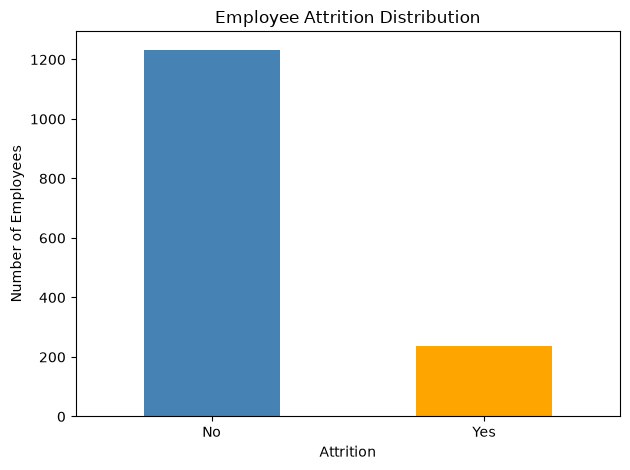


Attrition percentage:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


In [7]:
import matplotlib.pyplot as plt

print("Dataset shape:", df.shape)
print("\nAttrition counts:")
print(df["Attrition"].value_counts())

# Attrition distribution
df["Attrition"].value_counts().plot(
    kind="bar",
    color=["steelblue", "orange"],
    rot=0,
    title="Employee Attrition Distribution"
)
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.savefig("../visualizations/attrition_distribution.png", dpi=150)
plt.show()

# Attrition percentage
print("\nAttrition percentage:")
print((df["Attrition"].value_counts(normalize=True) * 100).round(2))

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Remove identifier and constant columns
drop_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]
if "EmployeeNumber" in df.columns:
    drop_cols.append("EmployeeNumber")

X = df.drop(columns=list(set(["Attrition"] + drop_cols)))
y = df["Attrition"].map({"Yes": 1, "No": 0})

categorical_cols = X.select_dtypes(include="object").columns.tolist()
numeric_cols = X.select_dtypes(exclude="object").columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy: {accuracy:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Attrition", "Attrition"]
))

Accuracy: 0.752
ROC-AUC: 0.803

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.92      0.77      0.84       247
   Attrition       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



C:\Users\VISHALI\AppData\Local\Temp\ipykernel_48812\1140448136.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns.tolist()


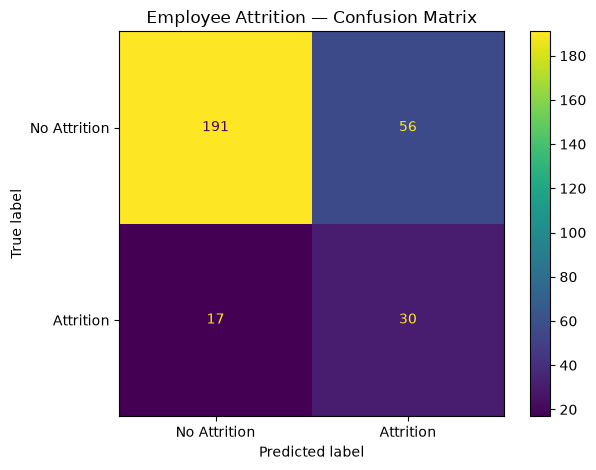

In [9]:
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=["No Attrition", "Attrition"]
).plot(values_format="d")

plt.title("Employee Attrition — Confusion Matrix")
plt.tight_layout()
plt.savefig("../visualizations/confusion_matrix.png", dpi=150)
plt.show()